In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('breast cancer dataset.csv')

In [3]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()

In [5]:
print(data.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [6]:
df = pd.DataFrame(data.data, columns=data.feature_names)

In [7]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
df['target'] = data.target

In [9]:
df.shape

(569, 31)

In [10]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [11]:
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
X = df.drop('target', axis=1)
y = df['target']

In [14]:
y.shape

(569,)

In [15]:
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [16]:
from sklearn.model_selection import train_test_split 

In [17]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [18]:
X_train.shape

(455, 30)

In [19]:
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(455,)
(114, 30)
(114,)


In [20]:
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [21]:
dtc = DecisionTreeClassifier()

In [22]:
dtc.fit(X_train,y_train)

DecisionTreeClassifier()

In [23]:
y_pred = dtc.predict(X_test)

In [24]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

In [25]:
print(accuracy_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(f1_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.9298245614035088
0.9436619718309859
0.9436619718309859
0.9436619718309859
[[39  4]
 [ 4 67]]


In [26]:
import matplotlib.pyplot as plt

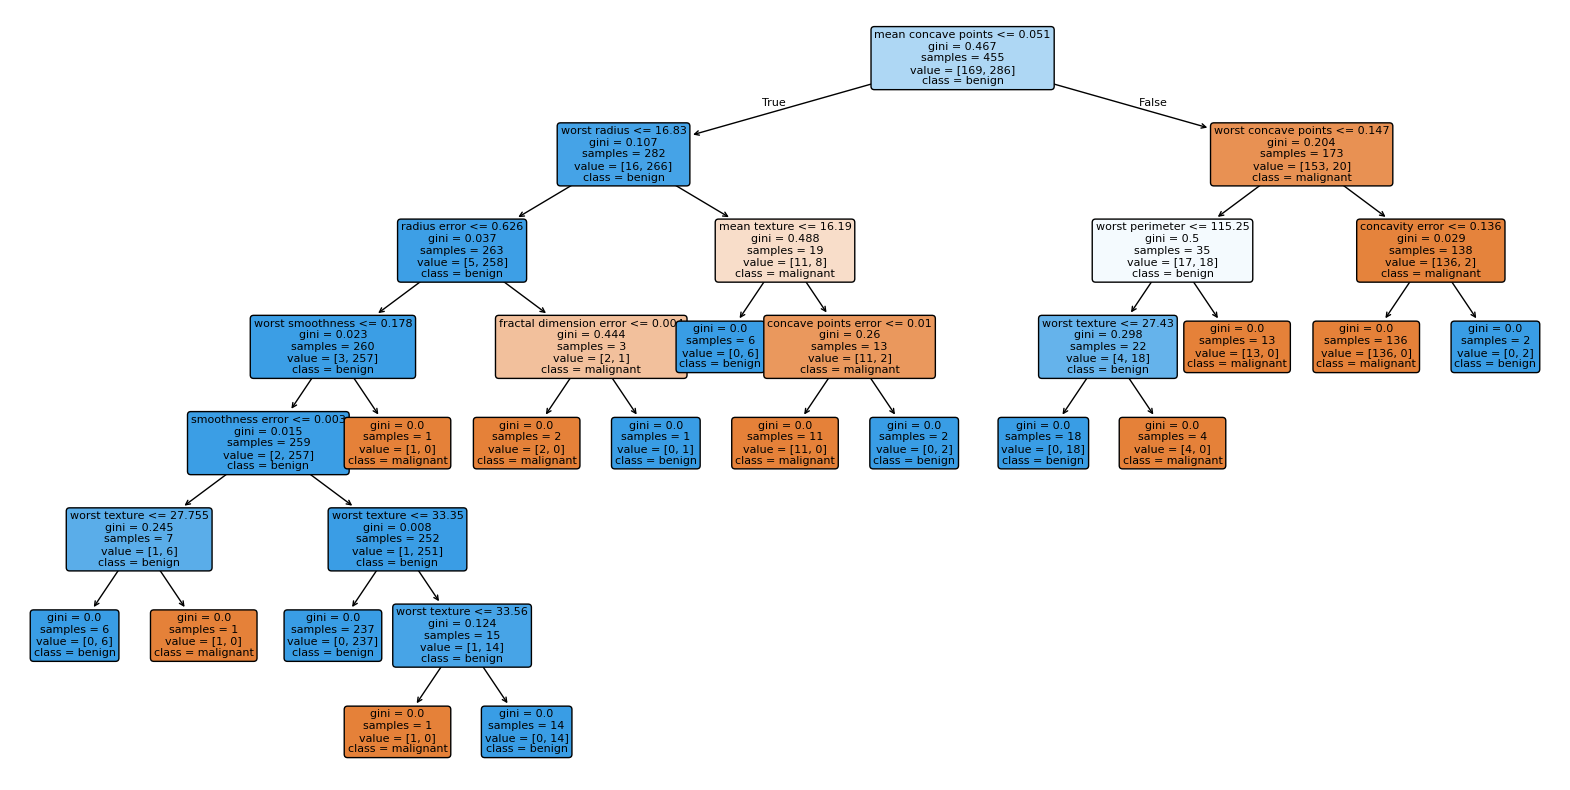

In [27]:
plt.figure(figsize=(20,10))
plot_tree(
    dtc,
    feature_names=X.columns,
    class_names=['malignant', 'benign'],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.show()

In [28]:
print("Tree Depth:", dtc.get_depth())
print("Number of Leaves:", dtc.get_n_leaves())

Tree Depth: 7
Number of Leaves: 16


In [33]:
dtc1 = DecisionTreeClassifier(max_depth=2)
dtc1.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=2)

In [34]:
y_pred = dtc1.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.9298245614035088


In [35]:
dtc2 = DecisionTreeClassifier(max_depth=4)
dtc2.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=4)

In [37]:
y_pred = dtc2.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.9385964912280702


In [38]:
dtc3 = DecisionTreeClassifier(max_depth=7)
dtc3.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=7)

In [39]:
y_pred = dtc3.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.9473684210526315


In [41]:
models = {
    "Depth 2": dtc1,
    "Depth 4": dtc2,
    "Depth 7": dtc3
}

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(name)
    print("Training Accuracy:", train_acc)
    print("Testing Accuracy:", test_acc)
    print("--------------------")

Depth 2
Training Accuracy: 0.9296703296703297
Testing Accuracy: 0.9298245614035088
--------------------
Depth 4
Training Accuracy: 0.9956043956043956
Testing Accuracy: 0.9385964912280702
--------------------
Depth 7
Training Accuracy: 1.0
Testing Accuracy: 0.9473684210526315
--------------------


# Pruning method

In [54]:
dtc_1 = DecisionTreeClassifier(max_depth=7,min_samples_split=2)
dtc_1.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=7)

In [55]:
y_pred = dtc_1.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.9385964912280702


In [56]:
dtc_2 = DecisionTreeClassifier(max_depth=7,min_samples_split=10)
dtc_2.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=7, min_samples_split=10)

In [57]:
y_pred = dtc_2.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.9298245614035088


In [58]:
dtc_3 = DecisionTreeClassifier(max_depth=7,min_samples_split=20)
dtc_3.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=7, min_samples_split=20)

In [59]:
y_pred = dtc_3.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.9298245614035088


In [60]:
models = {
    "Depth 2": dtc_1,
    "Depth 10": dtc_2,
    "Depth 20": dtc_3
}

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    print(name)
    print("Training Accuracy:", train_acc)
    print("Testing Accuracy:", test_acc)
    print("--------------------")

Depth 2
Training Accuracy: 1.0
Testing Accuracy: 0.9385964912280702
--------------------
Depth 10
Training Accuracy: 0.9956043956043956
Testing Accuracy: 0.9298245614035088
--------------------
Depth 20
Training Accuracy: 0.9758241758241758
Testing Accuracy: 0.9298245614035088
--------------------


# Implementation of decison tree using cross validation score

In [63]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    dtc,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("individual fold scores", scores)
print("Average accuracy:", scores.mean())

individual fold scores [0.92307692 0.89010989 0.91208791 0.9010989  0.93406593]
Average accuracy: 0.9120879120879121


# Implementation of decison tree using Gridsearcv

In [66]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [2,4,7],
    "min_samples_split": [2,10,20],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator = DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train,y_train)

print("best parameters:", grid_search.best_params_)
print("best CV accuracy:", grid_search.best_score_)

    
    

best parameters: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 10}
best CV accuracy: 0.9472527472527472


In [68]:
best_model = grid_search.best_estimator_
print(best_model)

DecisionTreeClassifier(criterion='entropy', max_depth=7, min_samples_split=10,
                       random_state=42)


In [70]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_best = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_best))


Test Accuracy: 0.956140350877193

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.91      0.94        43
           1       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Confusion Matrix:
 [[39  4]
 [ 1 70]]
